<a href="https://colab.research.google.com/github/ingjardt/android-training-1/blob/master/MAT160_oppstartsaktivitet_H26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT160 H26 – obligatorisk oppstartsaktivitet
## Feil og numerisk beregning

**Navn:** Håkon L. Strandjord  
**Frist:** Tirsdag 1. september 2026 kl. 23:59  
**Vurdering:** Godkjent / ikke godkjent

I denne oppstartsaktiviteten skal du arbeide med trunkeringsfeil, flyttallsfeil og tap av signifikante siffer. Den siste regneoppgaven forbereder temaet numerisk derivasjon, som vi starter med etter innleveringen.

Du kan samarbeide med andre, men alle skal levere sin egen notatbok og formulere sine egne forklaringer. Lever én `.ipynb`-fil i Mitt UiB. Bruk navnet ditt i filnavnet.

## Praktiske krav

Før du leverer:

- Kjør notatboken fra første til siste celle med **Restart and run all**.
- Kontroller at ingen celler gir feilmelding.
- Gi alle figurer aksetekster, tittel og forklaring (`legend`) når flere kurver vises.
- Svar på refleksjonsspørsmålene med hele setninger.
- Oppgi kilder og eventuell bruk av KI.

Du kan legge til så mange kode- og tekstceller du trenger.

In [63]:
import numpy as np
import matplotlib.pyplot as plt

print(f"NumPy-versjon: {np.__version__}")

NumPy-versjon: 2.1.3


# Oppgave 1 – trunkering


Taylorrekken til sinus om $x=0$ er

$$
\sin(x)=\sum_{k=0}^{\infty}\frac{(-1)^k x^{2k+1}}{(2k+1)!}.
$$

Når vi bare tar med et endelig antall ledd, får vi en numerisk approksimasjon.

### a) Implementasjon

Fullfør funksjonen `sin_taylor(x, n_ledd)`. Den skal beregne summen av de første `n_ledd` leddene i Taylorrekken. Bruk en løkke. `math.factorial(m)` beregner $m!$.

In [64]:
import math

def sin_taylor(x, n_ledd):
    tilnaerming = 0.0
    # Legger til de n første leddene i Taylorrekken til sin(x).
    for i in np.arange(0,n_ledd):
      tilnaerming=tilnaerming + (-1)**(i)*x**(2*i+1)/math.factorial(2*i+1)
    return tilnaerming

### b) Test funksjonen

Beregn approksimasjonen til $\sin(0.1)$ med 1, 2, 3, 4, 5 og 6 ledd. Sammenlign med `np.sin(0.1)`. Lag en tabell ved å skrive ut antall ledd, approksimasjonen og den absolutte feilen

$$
E_n=|\sin(0.1)-S_n(0.1)|.
$$

In [65]:
x = 0.1
n_verdier = np.arange(1, 7)
eksakt = np.sin(x)
feil = []
#Regner ut differansen av sin(0.1) og Taylor approksimasjon med 1 til 6 ledd.
for i in n_verdier:
  feil.append(abs(eksakt-sin_taylor(x,i)))
print(feil)

[np.float64(0.0001665833531718508), np.float64(8.331349481138783e-08), np.float64(1.983851971587569e-11), np.float64(2.7478019859472624e-15), np.float64(1.3877787807814457e-17), np.float64(1.3877787807814457e-17)]


### c) Visualiser feilen

Lag et plott av absolutt feil mot antall ledd. Bruk gjerne logaritmisk skala på feilaksen (`plt.semilogy`).

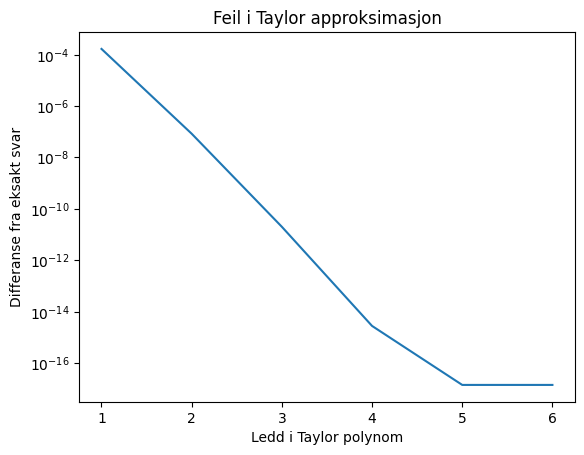

In [66]:
plt.semilogy(n_verdier,feil)

plt.xlabel("Ledd i Taylor polynom")

plt.ylabel("Differanse fra eksakt svar")

plt.title("Feil i Taylor approksimasjon")

plt.show()


### d) Forklaring

Forklar med egne ord:

1. Hva betyr trunkeringsfeil?
2. Hvorfor blir feilen mindre når antall ledd øker?
3. Blir resultatet nødvendigvis stadig bedre dersom vi fortsetter å legge til ledd på en datamaskin? Begrunn svaret.

**Svar:**
1. Ett Taylorpolynom er lik en funksjon i grensen. Siden datamaskiner ikke takler uendelige summer må man stoppe å legge sammen tall på ett tidspunkt for å få ett tall der er mulig å jobbe med. En trunkering av Taylorpolynomet refererer til Taylorutviklingen hvor man har stoppet summeringen på ett tidspunkt. Generelt kan man snakke om trunkeringer av alle uendelige konvergente summer.

2. Man kan bevise at $\sum_{i=1}^{\infty}a_{i}=L\in\mathbb{R}\Rightarrow\sum_{i=n}^{\infty}a_{i}\longrightarrow 0,$ når $n\rightarrow\infty$. Dette impliserer att feilen $E_{n}\approx\sum_{i=n}^{\infty}(-1)^{i}(0.1)^{2i+1}/(2i+1)!$ går imot null når antall ledd øker.

3. Nei. På ett tidspunkt har ikke datamaskinen nok bits til å representere approksimasjonen nøyaktig.

# Oppgave 2 – tap av signifikante siffer

Vi skal undersøke grenseverdien

$$
\lim_{x\to0}\frac{1-\cos(x)}{x^2}=\frac12.
$$

Direkte beregning kan bli unøyaktig fordi $\cos(x)$ ligger svært nær 1 når $x$ er liten. Ved å bruke identiteten

$$
1-\cos(x)=2\sin^2(x/2)
$$

kan uttrykket også skrives som

$$
\frac{2\sin^2(x/2)}{x^2}.
$$

### a) Implementer begge uttrykkene

In [67]:
def q_direkte(x):

    # TODO: Beregn (1-cos(x))/x**2.
    raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

def q_omskrevet(x):
    # TODO: Bruk det omskrevne uttrykket.
    raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

### b) Sammenlign feilene

Beregn begge uttrykkene for

$$x=10^{-1},10^{-2},\ldots,10^{-16}.$$

Lag et log-log-plott av absolutt feil mot $x$ for begge uttrykkene. Bruk $1/2$ som referanseverdi.

In [68]:
x_verdier = 10.0 ** (-np.arange(1, 17))
referanse = 0.5

# TODO: Beregn begge approksimasjonene og de absolutte feilene.
# TODO: Lag et log-log-plott med begge feilkurvene.
raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

NotImplementedError: Fullfør koden i denne cellen før du går videre.

### c) Forklaring

1. For hvilke verdier av $x$ begynner den direkte beregningen å gi dårlige resultater?
2. Hvor oppstår subtraksjon av nesten like tall?
3. Hvorfor er det omskrevne uttrykket mer numerisk stabilt?
4. Er feilen her først og fremst en trunkeringsfeil eller en avrundingsfeil?

**Svar:** Skriv svaret ditt her.

# Oppgave 3 – maskinpresisjon og avstand mellom flyttall

## a) Finn maskinepsilon

Start med `epsilon = 1.0` og halver verdien så lenge `1.0 + epsilon/2.0` fortsatt er forskjellig fra `1.0`. Når løkken stopper, skal `epsilon` være den minste verdien du fant slik at `1.0 + epsilon != 1.0`.

Sammenlign med `np.finfo(float).eps`.

In [ ]:
epsilon = 1.0

# TODO: Skriv while-løkken her.

print("Din verdi:       ", epsilon)
print("NumPy sin verdi: ", np.finfo(float).eps)

raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

## b) Avstanden ved andre størrelser

`np.spacing(A)` gir avstanden fra $A$ til det neste representerbare flyttallet i retning mot større tall.

Beregn avstanden for $A=1,10^3,10^9,10^{15}$. Forklar hvorfor avstanden øker når størrelsen på tallene øker.

In [ ]:
A_verdier = np.array([1.0, 1e3, 1e9, 1e15])

# TODO: Skriv ut A og np.spacing(A) for hver verdi.
raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

**Svar og forklaring:** Skriv her.

# Oppgave 4 – forberedelse til numerisk derivasjon

Den deriverte kan defineres som

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

På en datamaskin må vi bruke en positiv, endelig verdi av $h$. Vi undersøker derfor approksimasjonen

$$
D_hf(x)=\frac{f(x+h)-f(x)}{h}
$$

for $f(x)=e^x$ ved $x=1$. Den eksakte deriverte er $f'(1)=e$.

### a) Beregn approksimasjonene

Implementer `fremoverdifferanse`. Beregn approksimasjonen og absolutt feil for

$$h=10^{-1},10^{-2},\ldots,10^{-16}.$$

In [ ]:
def fremoverdifferanse(f, x, h):
    # TODO: Implementer formelen D_h f(x).
    pass

f = np.exp
x0 = 1.0
h_verdier = 10.0 ** (-np.arange(1, 17))
eksakt_derivert = np.e

# TODO: Beregn approksimasjoner og absolutte feil.
raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

### b) Lag en figur

Lag et log-log-plott av absolutt feil mot $h$. Marker gjerne den verdien av $h$ som gir minst feil.

In [ ]:
# TODO: Lag figuren og skriv ut verdien av h som gir minst feil.
raise NotImplementedError("Fullfør koden i denne cellen før du går videre.")

### c) Beskriv observasjonen

1. Omtrent hvilken verdi av $h$ gir minst feil?
2. Hvorfor tror du feilen først avtar når $h$ blir mindre?
3. Hvorfor tror du feilen senere øker?
4. Hvilken del av beregningen innebærer subtraksjon av nesten like tall?

Du trenger ikke utlede en feilformel. Dette gjør vi i forelesningen om numerisk derivasjon.

**Svar:** Skriv svaret ditt her.

# Refleksjon over bruk av KI

Beskriv kort eventuell bruk av KI-verktøy i arbeidet.

- Hvilket verktøy brukte du?
- Hva brukte du det til?
- Hvordan kontrollerte du at kode, forklaringer eller kilder var riktige?
- Hva gjorde du selv for å forstå resultatet?

Det er også helt greit å skrive at du ikke brukte KI.

**Svar:** Skriv refleksjonen din her.

# Sjekkliste før levering

Kryss av ved å endre `[ ]` til `[x]`.

- [ ] Navnet mitt står øverst i notatboken.
- [ ] Jeg har besvart alle fire obligatoriske oppgaver.
- [ ] Jeg har kjørt **Restart and run all**.
- [ ] Alle celler kjører uten feilmeldinger.
- [ ] Alle figurer har aksetekster og tittel.
- [ ] Jeg har forklart resultatene med egne ord.
- [ ] Jeg har beskrevet eventuell bruk av KI.
- [ ] Filnavnet inneholder navnet mitt.

## Kriterier for godkjenning

For å få aktiviteten godkjent må:

- notatboken kunne kjøres i riktig rekkefølge,
- de numeriske beregningene være i hovedsak riktige,
- figurene være lesbare og korrekt merket,
- observasjonene være forklart med egne ord,
- eventuell bruk av KI være oppgitt.

Dersom besvarelsen ikke blir godkjent første gang, får du anledning til å rette den.